In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


import pickle
import os

from sentence_transformers import SentenceTransformer

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from sklearn.decomposition import PCA

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
import pandas as pd
import os

DATA_DIR = os.path.expanduser(
    "~/Book-Recommendation-System/data"
)

books_path = os.path.join(DATA_DIR, "BX-Books.csv")
descriptions_path = os.path.join(
    DATA_DIR, "Books_Descriptions.csv"
)

books = pd.read_csv(
    books_path,
    sep=";",
    encoding="latin-1",
    engine="python",
    on_bad_lines="warn"
)

descriptions = pd.read_csv(
    descriptions_path,
    encoding="latin-1",
    engine="python",
    on_bad_lines="warn"
)

print("Books shape:", books.shape)
print("Descriptions shape:", descriptions.shape)


Books shape: (270491, 8)
Descriptions shape: (7021, 3)


In [6]:
merged_books = pd.merge(
    books,
    descriptions,
    on="ISBN",
    how="inner"
)

print("Merged dataset shape:", merged_books.shape)

merged_books.head()

Merged dataset shape: (7009, 10)


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L,Unnamed: 0,description
0,0684823802,OUT OF THE SILENT PLANET,C.S. Lewis,1996,Scribner,http://images.amazon.com/images/P/0684823802.0...,http://images.amazon.com/images/P/0684823802.0...,http://images.amazon.com/images/P/0684823802.0...,56035,Dr. Ransom is abducted to the eerie red planet...
1,0679810307,Shabanu: Daughter of the Wind (Border Trilogy),SUZANNE FISHER STAPLES,1991,Laurel Leaf,http://images.amazon.com/images/P/0679810307.0...,http://images.amazon.com/images/P/0679810307.0...,http://images.amazon.com/images/P/0679810307.0...,24919,"Shabanu, a young nomad of the Cholistan Desert..."
2,0345260317,The Dragons of Eden: Speculations on the Evolu...,Carl Sagan,1978,Ballantine Books,http://images.amazon.com/images/P/0345260317.0...,http://images.amazon.com/images/P/0345260317.0...,http://images.amazon.com/images/P/0345260317.0...,3695,Dr. Carl Sagan Takes Us on a Great Reading Adv...
3,0671042858,The Girl Who Loved Tom Gordon,Stephen King,2000,Pocket,http://images.amazon.com/images/P/0671042858.0...,http://images.amazon.com/images/P/0671042858.0...,http://images.amazon.com/images/P/0671042858.0...,1074,The acclaimed #1 New York Times and undisputed...
4,037582345X,"The Golden Compass (His Dark Materials, Book 1)",PHILIP PULLMAN,2002,Knopf Books for Young Readers,http://images.amazon.com/images/P/037582345X.0...,http://images.amazon.com/images/P/037582345X.0...,http://images.amazon.com/images/P/037582345X.0...,15057,Living among scholars in the hallowed halls of...


In [7]:
# Dataset information
print("Dataset Information:")
print("-" * 50)

print("Shape:", merged_books.shape)

print("\nColumn Names:")
print(merged_books.columns.tolist())

print("\nData Types:")
print(merged_books.dtypes)

print("\nMissing Values:")
print(merged_books.isnull().sum())

print("\nDuplicate ISBNs:")
print(merged_books["ISBN"].duplicated().sum())

print("\nDuplicate Book Titles:")
print(merged_books["Book-Title"].duplicated().sum())

Dataset Information:
--------------------------------------------------
Shape: (7009, 10)

Column Names:
['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'Image-URL-S', 'Image-URL-M', 'Image-URL-L', 'Unnamed: 0', 'description']

Data Types:
ISBN                     str
Book-Title               str
Book-Author              str
Year-Of-Publication    int64
Publisher                str
Image-URL-S              str
Image-URL-M              str
Image-URL-L              str
Unnamed: 0             int64
description              str
dtype: object

Missing Values:
ISBN                   0
Book-Title             0
Book-Author            0
Year-Of-Publication    0
Publisher              0
Image-URL-S            0
Image-URL-M            0
Image-URL-L            0
Unnamed: 0             0
description            0
dtype: int64

Duplicate ISBNs:
0

Duplicate Book Titles:
0


In [8]:
# Calculate description length
merged_books["description_length"] = (
    merged_books["description"]
    .str.split()
    .str.len()
)

print("Description Length Statistics:")
print(merged_books["description_length"].describe())

Description Length Statistics:
count    7009.000000
mean       50.921387
std        55.402736
min         1.000000
25%        22.000000
50%        33.000000
75%        50.000000
max       701.000000
Name: description_length, dtype: float64


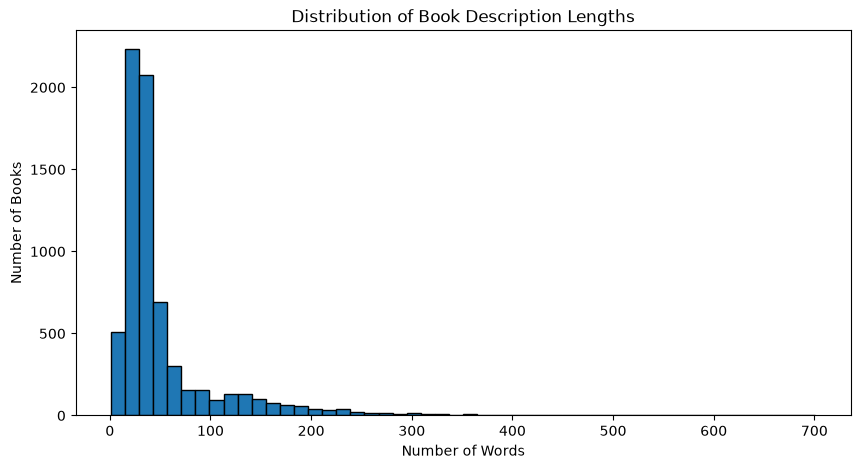

In [9]:
plt.figure(figsize=(10, 5))

plt.hist(
    merged_books["description_length"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Book Description Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Books")

plt.show()

In [10]:
short_descriptions = merged_books[
    merged_books["description_length"] < 10
]

print("Books with fewer than 10 words:",
      len(short_descriptions))

short_descriptions[
    ["Book-Title", "description", "description_length"]
].head(20)

Books with fewer than 10 words: 183


,Book-Title,description,description_length
44,Fall Of Shane Mackade (The Mackade Brothers) (...,Romance,1
188,Cyrano De Bergerac (Collection Folio),Lecture suivie,2
203,Handbuch des Kriegers des Lichts.,"Maximen zur LebensfÃ¼hrung, gekleidet in eine ...",8
237,"Barney's Favorite Mother Goose Rhymes, Volume I",Traditional and new rhymes featuring Barney.,6
280,"Life at Blandings: Something Fresh, Summer Lig...","Contents: SOMETHING FRESH, SUMMER LIGHTNING, a...",8
282,Shelley (Penguin Poetry Library),Selected by Isabel Quigley,4
320,Wash Your Hair With Whipped Cream,Hundreds of offbeat uses for brand-name products.,7
344,War Talk,Essays.,1
417,A Light in the Attic,Poems and drawings by Shel Silverstein.,6
421,KLINGON GAMBIT,Juvenile fiction.,2


In [11]:
long_descriptions = merged_books.sort_values(
    by="description_length",
    ascending=False
)

long_descriptions[
    ["Book-Title", "description_length"]
].head(10)

,Book-Title,description_length
1921,"Little House (9 Books, Boxed Set)",701
6375,The Ship: Retracing Captain Cook's Endeavor Vo...,516
3835,A Simple Shaker Murder (Sister Rose Callahan M...,505
55,The Threatening Storm: The Case for Invading Iraq,495
1388,That Dorky Homemade Look: Quilting Lessons fro...,492
1396,The Multicultiboho Show,491
3568,How to Make Love Like a Porn Star: A Cautionar...,479
4596,Flora's Suitcase: A Novel,434
1618,Mondo Desperado,405
4938,Conversing With the Planets: How Science and M...,400


In [12]:
import os

PROJECT_DIR = os.path.expanduser(
    "~/Book-Recommendation-System"
)

for root, dirs, files in os.walk(PROJECT_DIR):
    for file in files:
        if file.endswith(".npy") or file.endswith(".pkl"):
            print(os.path.join(root, file))

/home/user/Book-Recommendation-System/venv/lib/python3.12/site-packages/numpy/lib/tests/data/python3.npy
/home/user/Book-Recommendation-System/venv/lib/python3.12/site-packages/numpy/lib/tests/data/py3-objarr.npy
/home/user/Book-Recommendation-System/venv/lib/python3.12/site-packages/numpy/lib/tests/data/win64python2.npy
/home/user/Book-Recommendation-System/venv/lib/python3.12/site-packages/numpy/lib/tests/data/py2-np0-objarr.npy
/home/user/Book-Recommendation-System/venv/lib/python3.12/site-packages/numpy/lib/tests/data/py2-objarr.npy
/home/user/Book-Recommendation-System/venv/lib/python3.12/site-packages/numpy/_core/tests/data/astype_copy.pkl
/home/user/Book-Recommendation-System/venv/lib/python3.12/site-packages/joblib/test/data/joblib_0.9.2_pickle_py35_np19.pkl_04.npy
/home/user/Book-Recommendation-System/venv/lib/python3.12/site-packages/joblib/test/data/joblib_0.9.2_pickle_py34_np19.pkl_04.npy
/home/user/Book-Recommendation-System/venv/lib/python3.12/site-packages/joblib/test/da

In [13]:
from sentence_transformers import SentenceTransformer

semantic_model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

print("Sentence Transformer model loaded successfully!")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Sentence Transformer model loaded successfully!


In [14]:
book_descriptions = merged_books["description"].tolist()

book_embeddings = semantic_model.encode(
    book_descriptions,
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True,
    convert_to_numpy=True
)

print("Embedding shape:", book_embeddings.shape)
print("Data type:", book_embeddings.dtype)

Batches:   0%|          | 0/220 [00:00<?, ?it/s]

Embedding shape: (7009, 384)
Data type: float32


In [15]:
import os
import numpy as np

MODEL_DIR = os.path.join(PROJECT_DIR, "models")

os.makedirs(MODEL_DIR, exist_ok=True)

np.save(
    os.path.join(MODEL_DIR, "book_embeddings.npy"),
    book_embeddings
)

merged_books.to_pickle(
    os.path.join(MODEL_DIR, "merged_books.pkl")
)

print("Embeddings and dataset saved successfully!")

Embeddings and dataset saved successfully!


In [16]:
import numpy as np
import pandas as pd
import os

MODEL_DIR = os.path.join(PROJECT_DIR, "models")

book_embeddings = np.load(
    os.path.join(MODEL_DIR, "book_embeddings.npy")
)

merged_books = pd.read_pickle(
    os.path.join(MODEL_DIR, "merged_books.pkl")
)

print("Dataset shape:", merged_books.shape)
print("Embedding shape:", book_embeddings.shape)

Dataset shape: (7009, 11)
Embedding shape: (7009, 384)


In [17]:
from sklearn.cluster import KMeans

# Initialize K-Means
final_kmeans = KMeans(
    n_clusters=9,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=42
)

# Train the model and assign clusters
final_labels = final_kmeans.fit_predict(book_embeddings)

# Add cluster labels to dataset
merged_books["Cluster"] = final_labels

print("K-Means model trained successfully!")
print("Number of clusters:", len(np.unique(final_labels)))
print("Inertia:", final_kmeans.inertia_)
print("Iterations:", final_kmeans.n_iter_)

K-Means model trained successfully!
Number of clusters: 9
Inertia: 5496.82373046875
Iterations: 45


In [18]:
cluster_counts = merged_books["Cluster"].value_counts().sort_index()

print("Cluster Distribution:")
print(cluster_counts)

Cluster Distribution:
Cluster
0     234
1    1338
2     621
3     790
4     889
5    1183
6     871
7     407
8     676
Name: count, dtype: int64


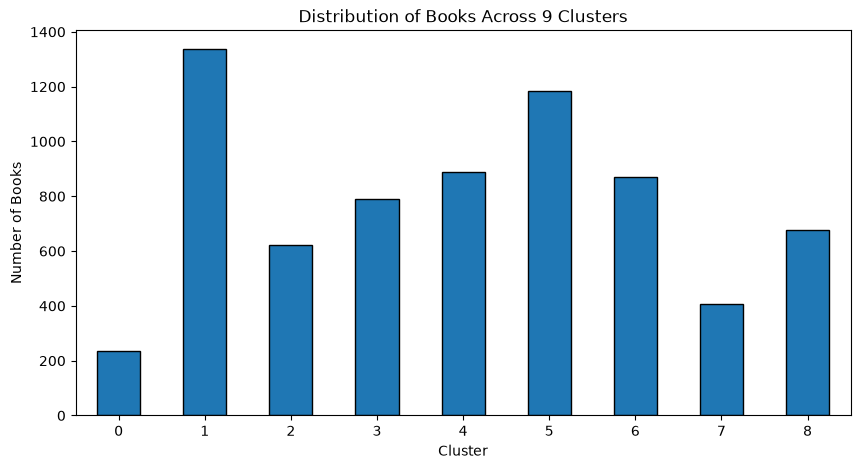

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

cluster_counts.plot(kind="bar", edgecolor="black")

plt.title("Distribution of Books Across 9 Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)

plt.show()

In [20]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Silhouette score using cosine distance
silhouette = silhouette_score(
    book_embeddings,
    final_labels,
    metric="cosine",
    sample_size=2000,
    random_state=42
)

# Other metrics use Euclidean distance
db_score = davies_bouldin_score(
    book_embeddings,
    final_labels
)

ch_score = calinski_harabasz_score(
    book_embeddings,
    final_labels
)

print("MODEL EVALUATION")
print("-" * 40)
print("Silhouette Score:", silhouette)
print("Davies-Bouldin Index:", db_score)
print("Calinski-Harabasz Index:", ch_score)

MODEL EVALUATION
----------------------------------------
Silhouette Score: 0.0580800361931324
Davies-Bouldin Index: 4.391080041216742
Calinski-Harabasz Index: 112.93893820450735


In [21]:
for cluster in sorted(merged_books["Cluster"].unique()):

    print(f"\n{'='*70}")
    print(f"CLUSTER {cluster}")
    print(f"{'='*70}")

    cluster_books = merged_books[
        merged_books["Cluster"] == cluster
    ]

    print("Total books:", len(cluster_books))

    sample_books = cluster_books.sample(
        min(15, len(cluster_books)),
        random_state=42
    )

    for _, row in sample_books.iterrows():
        print(
            f"{row['Book-Title']} - {row['Book-Author']}"
        )


CLUSTER 0
Total books: 234
Lenfant Et La Riviere - Henri Bosco
Von der Liebe und anderen DÃ?Â¤monen. - Gabriel Garcia Marquez
L'ombre pourpre. 1, L'Ã?Â©pÃ?Â©e de Bedwyr - R. A Salvatore
Chocolat. Das Buch zum Film. - Joanne Harris
Oceano mare - Alessandro Baricco
Les Miroirs de l'esprit - Norman Spinrad
In nomine patris - Zamponi Francis
Die vollkommene Freude. - Luise Rinser
Montaigne - GaÃ?Â«l Gauvin
Pequenas Infamias: Premio Planeta 1998 (Autores Espanoles E Iberoamericanos) - Carmen Posadas
Herr Puntila und sein Knecht Matti. VolksstÃ?Â¼ck. - Bertolt Brecht
Meneer Foppe en het gedoe - Wim de Bie
Garzanti - Gli Elefanti: I Mari Del Sud - Montalban
Le vaisseau des voyageurs - Robert Charles Wilson
 Clifford Visita El Hospital (Clifford El Gran Perro Colorado) - Norman Bridwell

CLUSTER 1
Total books: 1338
The Little Match Girl (Sandcastle Books) - Hans Christian Andersen
On My Honor: Lesbians Reflect on Their Scouting Experience - Nancy Manahan
The Yokota Officers Club - SARAH BIRD


In [22]:
import joblib
import os

MODEL_DIR = os.path.join(PROJECT_DIR, "models")

os.makedirs(MODEL_DIR, exist_ok=True)

# Save trained K-Means model
joblib.dump(
    final_kmeans,
    os.path.join(MODEL_DIR, "kmeans_model.pkl")
)

# Save clustered dataset
merged_books.to_pickle(
    os.path.join(MODEL_DIR, "clustered_books.pkl")
)

# Save cluster labels
np.save(
    os.path.join(MODEL_DIR, "cluster_labels.npy"),
    final_labels
)

print("Final K-Means model saved successfully!")
print("Clustered dataset saved successfully!")
print("Cluster labels saved successfully!")

Final K-Means model saved successfully!
Clustered dataset saved successfully!
Cluster labels saved successfully!
